<h1 style="color:;">CIFAR-10 EDA for our SimCLR project</h1>


<h3 style="color:#8B0000;">Setup</h3>
<div style="border-left:4px solid #550000; background:#f6f8fa; color:#222; padding:6px 12px;">Load the libraries and set the folder names. Change the paths if your folders are named differently.</div>

In [21]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageEnhance
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split

# Folder and file names
CSV_PATH = "trainLabels.csv"
TRAIN_DIR = "train"

# Fixed seed so we get the same random results every run
np.random.seed(42)

<h1 style="color:#B22222; border-bottom:3px solid #8B0000; padding-bottom:4px;">EDA</h1>
<p>What is in the data and is it clean?</p>

<h3 style="color:#B22222;">1.1 Dataset size and class balance</h3>
<div style="border-left:4px solid #550000; background:#f6f8fa; color:#222; padding:6px 12px;">How many images and classes do we have? If every class has the same number of images, plain accuracy is a fair way to score our model.</div>

Total images: 50000
Number of classes: 10
Images per class:
label
airplane      5000
automobile    5000
bird          5000
cat           5000
deer          5000
dog           5000
frog          5000
horse         5000
ship          5000
truck         5000
Name: count, dtype: int64


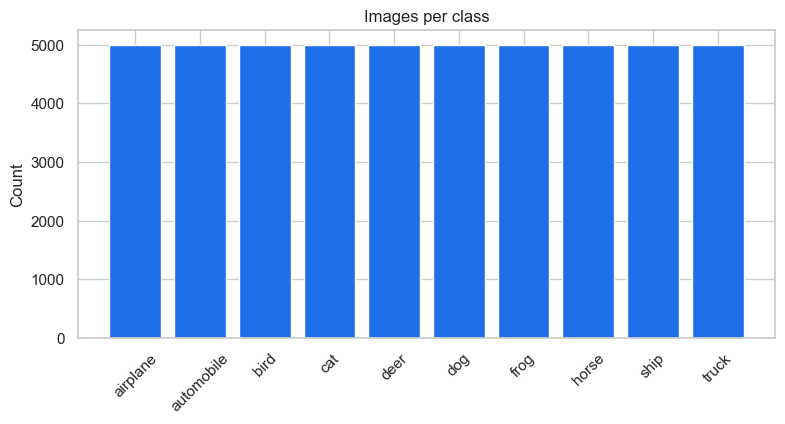

In [22]:
df = pd.read_csv(CSV_PATH)
classes = sorted(df["label"].unique())
counts = df["label"].value_counts().reindex(classes)

print("Total images:", len(df))
print("Number of classes:", len(classes))
print("Images per class:")
print(counts)

plt.figure(figsize=(9, 4))
plt.bar(counts.index, counts.values, color="#1f6feb")
plt.title("Images per class")
plt.xticks(rotation=45)
plt.ylabel("Count")
plt.show()

<div style="border-left:5px solid #0b3c5d; background:#eaf3f9; color:#222; padding:8px 14px;">
<b style="color:#0b3c5d;">What this tells us</b>
<ul>
<li>The dataset has <b style="color:#e4572e;">50,000 images</b> in <b style="color:#6a4c93;">10 classes</b>.</li>
<li>Every class has exactly <b style="color:#e4572e;">5,000 images</b>, so the data is <b style="color:#2e8b57;">perfectly balanced</b> (all bars are the same height).</li>
<li>Because of this, <b style="color:#2e8b57;">accuracy is a fair metric</b>. A model that guesses randomly would score about <b style="color:#e4572e;">10%</b>.</li>
<li>We do <b style="color:#c1121f;">not</b> need class weights, oversampling or undersampling.</li>
</ul>
</div>

<h3 style="color:#B22222;">1.2 Check the images are fine</h3>
<div style="border-left:4px solid #550000; background:#f6f8fa; color:#222; padding:6px 12px;">Make sure no image file is missing or broken and that there are no duplicate ids. This also loads all images into one array called <code>X</code> so we can reuse it below. It takes a minute or two.</div>

In [24]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate ids:", df["id"].duplicated().sum())

X = np.zeros((len(df), 32, 32, 3), dtype=np.uint8)
bad = 0

for i in range(len(df)):
    path = TRAIN_DIR + "/" + str(df["id"][i]) + ".png"
    try:
        X[i] = np.array(Image.open(path).convert("RGB"))
    except Exception:
        bad = bad + 1

print("Missing or broken images:", bad)

# Turn class names into numbers (0 to 9)
y = df["label"].map({name: n for n, name in enumerate(classes)}).values

Missing values: 0
Duplicate ids: 0
Missing or broken images: 0


<div style="border-left:5px solid #5b2a86; background:#f4eefb; color:#222; padding:8px 14px;">
<b style="color:#5b2a86;">What this tells us</b>
<ul>
<li><b style="color:#2b8a3e;">No missing values</b> in the table: every image has an id and a label.</li>
<li><b style="color:#2b8a3e;">No duplicate ids</b>, so no image is listed twice in the CSV.</li>
<li><b style="color:#c77d00;">0 missing or broken images</b>: all <b style="color:#c77d00;">50,000</b> files exist, open correctly and fit the expected <b style="color:#0b7285;">32x32 RGB</b> shape.</li>
<li>The data is <b style="color:#2b8a3e;">clean</b>, so we do <b style="color:#c1121f;">not</b> need to remove or repair anything and can use all of it.</li>
</ul>
</div>

<h3 style="color:#8B0000;">1.3 Look at the images</h3>
<div style="border-left:4px solid #B22222; background:#f6f8fa; color:#222; padding:6px 12px;">Show 5 random images from every class. This shows how different images of the same class can look.</div>

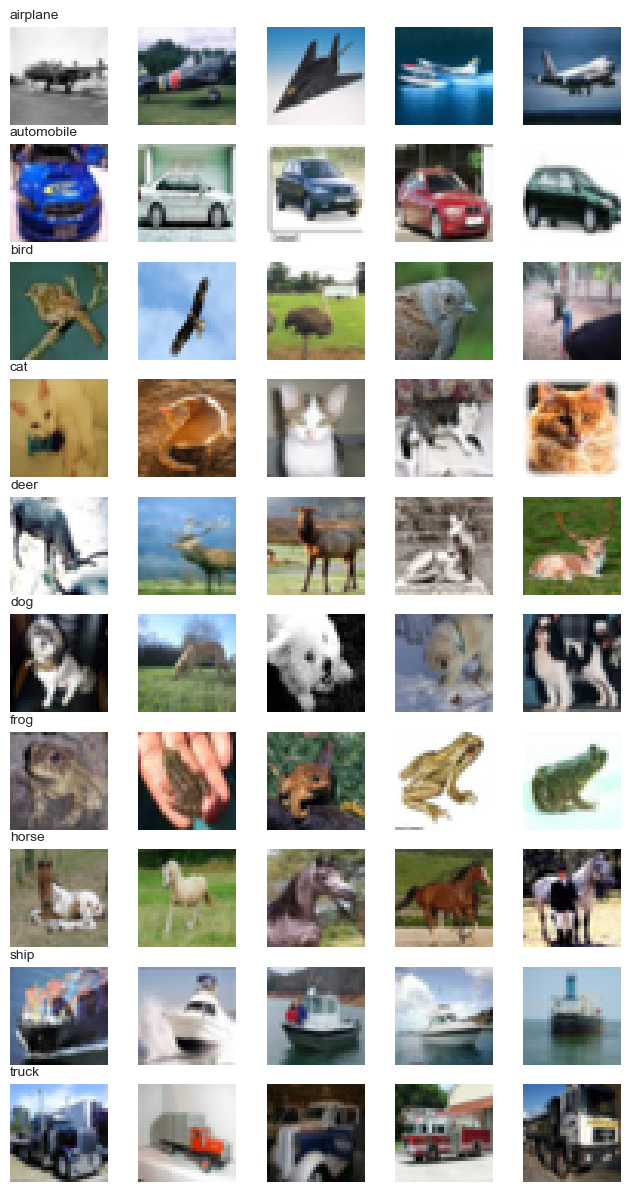

In [25]:
fig, axes = plt.subplots(10, 5, figsize=(8, 15))

for row in range(10):
    ids = np.where(y == row)[0]
    chosen = np.random.choice(ids, 5, replace=False)
    for col in range(5):
        axes[row, col].imshow(X[chosen[col]])
        axes[row, col].axis("off")
    axes[row, 0].set_title(classes[row], loc="left", fontsize=10)

plt.show()

<div style="border-left:5px solid #0b7285; background:#e8f6f8; color:#222; padding:8px 14px;">
<b style="color:#0b7285;">What this tells us</b>
<ul>
<li>Images of the <b style="color:#d6336c;">same class look very different</b>: the pose, zoom, background and colour all change (for example, the five horses or the five trucks).</li>
<li>Many classes have a <b style="color:#5f3dc4;">typical background</b>: airplanes on sky, ships on water, deer and horses on grass. A model could learn the background instead of the object.</li>
<li>The images are <b style="color:#e8590c;">tiny (32x32) and blurry</b>, and a few are <b style="color:#e8590c;">hard to recognise even for a person</b> (some cat and dog images).</li>
<li>Some images are <b style="color:#2b8a3e;">grayscale or on white backgrounds</b>, so colour is not always reliable.</li>
<li>So the model must learn the <b style="color:#0b7285;">shape of the object</b>, not just the colour or background. This is why <b style="color:#d6336c;">strong augmentation</b> (crop and colour change) is needed in SimCLR.</li>
</ul>
</div>

<h3 style="color:#B22222;">1.4 Pixel statistics</h3>
<div style="border-left:4px solid #8B0000; background:#f6f8fa; color:#222; padding:6px 12px;">The smallest and largest pixel value, and the average and spread (std) of each colour. We will need these numbers later to normalise the images before training.</div>

In [26]:
print("Pixel values go from", X.min(), "to", X.max())

mean = X.mean(axis=(0, 1, 2)) / 255
std = X.std(axis=(0, 1, 2)) / 255
print("Mean (R, G, B):", mean.round(3))
print("Std  (R, G, B):", std.round(3))

Pixel values go from 0 to 255
Mean (R, G, B): [0.491 0.482 0.447]
Std  (R, G, B): [0.247 0.243 0.262]


<div style="border-left:5px solid #343a40; background:#f1f3f5; color:#222; padding:8px 14px;">
<b style="color:#343a40;">What this tells us</b>
<ul>
<li>Pixel values use the full range, <b style="color:#1971c2;">0 to 255</b>, so the images are standard 8-bit colour with no odd scaling.</li>
<li>The average of each channel is close to the middle: <b style="color:#d6336c;">R = 0.491, G = 0.482, B = 0.447</b> (on a 0 to 1 scale). The images are neither mostly dark nor mostly bright.</li>
<li><b style="color:#1971c2;">Blue has the lowest mean</b> and the <b style="color:#1971c2;">highest spread</b> (std 0.262). Red and green are very similar to each other (std 0.247 and 0.243).</li>
<li>The std is about <b style="color:#d6336c;">0.25</b> for every channel, so pixel values vary a lot from image to image.</li>
<li>We will use these numbers to <b style="color:#2f9e44;">normalise the images</b> (subtract the mean, divide by the std) so each channel is centred at 0 with a similar scale. This makes training more stable.</li>
</ul>
</div>

<h3 style="color:#8B0000;">1.5 Brightness by class</h3>
<div style="border-left:4px solid #B22222; background:#f6f8fa; color:#222; padding:6px 12px;">Brightness is the average pixel value of an image. The boxplot shows if some classes have darker or brighter images than others.</div>

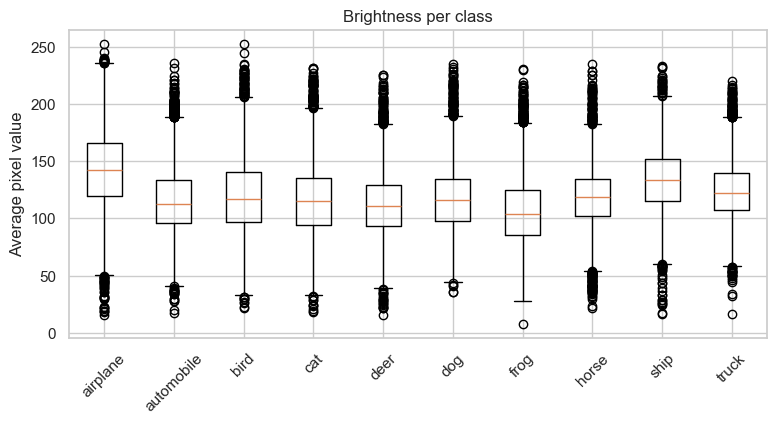

In [27]:
brightness = X.mean(axis=(1, 2, 3))

data = [brightness[y == n] for n in range(10)]
plt.figure(figsize=(9, 4))
plt.boxplot(data)
plt.title("Brightness per class")
plt.xticks(range(1, 11), classes, rotation=45)
plt.ylabel("Average pixel value")
plt.show()

<div style="border-left:5px solid #d9480f; background:#fff3e8; color:#222; padding:8px 14px;">
<b style="color:#d9480f;">What this tells us</b>
<ul>
<li><b style="color:#1971c2;">Airplane</b> images are the brightest (median about <b style="color:#c2255c;">142</b>) and <b style="color:#1971c2;">ship</b> is second (about <b style="color:#c2255c;">133</b>). This fits their sky and water backgrounds.</li>
<li><b style="color:#1971c2;">Frog</b> is the darkest class (median about <b style="color:#c2255c;">104</b>), likely because of dark, earthy scenes.</li>
<li>The other classes sit close together, with medians around <b style="color:#c2255c;">110 to 122</b>.</li>
<li>Every class has <b style="color:#7048e8;">very dark outliers</b> (below 50) and <b style="color:#7048e8;">very bright outliers</b> (above 200), so lighting varies a lot inside each class.</li>
<li>The boxes <b style="color:#2b8a3e;">overlap heavily</b>, so brightness alone cannot tell the classes apart. But there is a small link between brightness and class, so the model could use it as a shortcut.</li>
<li>This supports using <b style="color:#2b8a3e;">brightness and colour augmentation</b> in SimCLR, so the model learns the object instead of the lighting.</li>
</ul>
</div>

<h3 style="color:#550000;">1.6 Average colour by class</h3>
<div style="border-left:4px solid #B22222; background:#f6f8fa; color:#222; padding:6px 12px;">The average red, green and blue of each class. If classes have very different colours, SimCLR could match images by colour alone, which is why colour changes are part of its augmentations.</div>

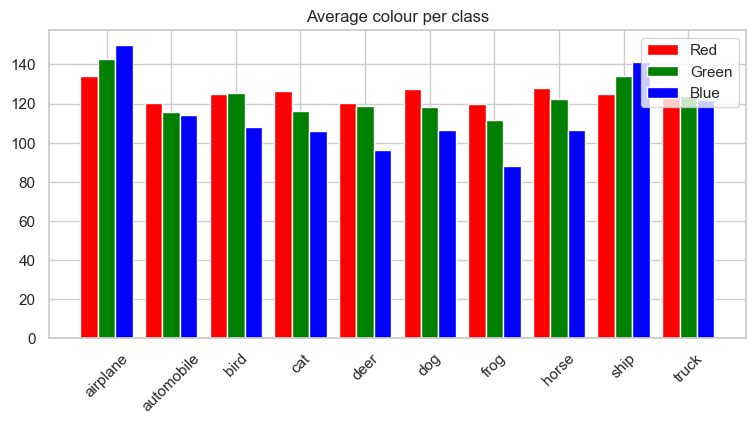

In [28]:
colour_means = []
for n in range(10):
    colour_means.append(X[y == n].mean(axis=(0, 1, 2)))
colour_means = np.array(colour_means)

positions = np.arange(10)
plt.figure(figsize=(9, 4))
plt.bar(positions - 0.27, colour_means[:, 0], width=0.27, color="red", label="Red")
plt.bar(positions, colour_means[:, 1], width=0.27, color="green", label="Green")
plt.bar(positions + 0.27, colour_means[:, 2], width=0.27, color="blue", label="Blue")
plt.xticks(positions, classes, rotation=45)
plt.legend()
plt.title("Average colour per class")
plt.show()

<div style="border-left:5px solid #862e9c; background:#f8f0fc; color:#222; padding:8px 14px;">
<b style="color:#862e9c;">What this tells us</b>
<ul>
<li><b style="color:#1971c2;">Airplane</b> and <b style="color:#1971c2;">ship</b> are the only classes where <b style="color:#1c7ed6;">blue is the strongest channel</b> (airplane about 150, ship about 141). This matches their sky and water backgrounds.</li>
<li><b style="color:#e8590c;">Frog, deer, cat, dog, horse and bird</b> are <b style="color:#e03131;">red-heavy with low blue</b>. Frog has the lowest blue of all (about 88) and deer is next (about 96), which fits grass, soil and brown animals.</li>
<li><b style="color:#2f9e44;">Automobile and truck</b> are close to <b style="color:#2f9e44;">neutral</b>, with R, G and B all within a few points of each other (about 115 to 123).</li>
<li>So <b style="color:#862e9c;">average colour is linked to class</b>. Colour alone could hint at the class, though the differences are modest.</li>
<li>This matters for SimCLR: two crops of the same image have a similar colour, so the model could match them by <b style="color:#e03131;">colour alone</b> and skip learning the object. That is why <b style="color:#2f9e44;">colour jitter and random grayscale</b> are part of the augmentations.</li>
</ul>
</div>

<h3 style="color:#B22222;">1.7 Augmentation preview</h3>
<div style="border-left:4px solid #550000; background:#f6f8fa; color:#222; padding:6px 12px;">SimCLR makes two changed copies (views) of each image and learns that they belong together. Here is a simple version of those changes: random crop, flip, colour change and sometimes grayscale.</div>

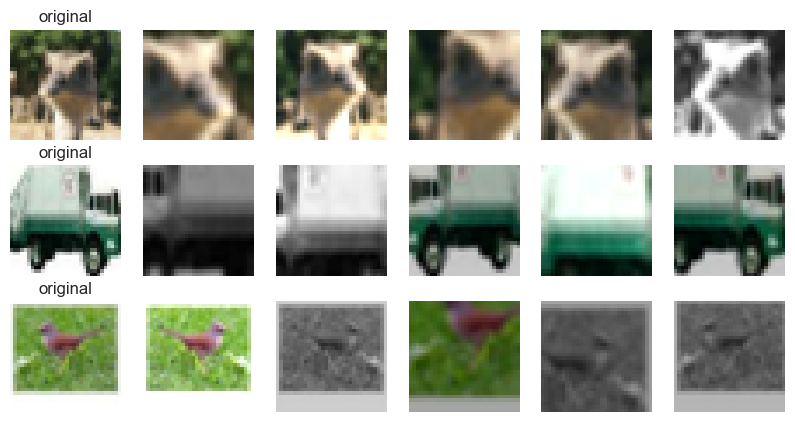

In [30]:
def augment(img):
    # Random crop of size 16 to 32 pixels, then resize back to 32x32
    size = np.random.randint(16, 33)
    left = np.random.randint(0, 33 - size)
    top = np.random.randint(0, 33 - size)
    img = img.crop((left, top, left + size, top + size)).resize((32, 32))

    # Flip left-right half of the time
    if np.random.rand() < 0.5:
        img = img.transpose(Image.FLIP_LEFT_RIGHT)

    # Change brightness and colour strength
    img = ImageEnhance.Brightness(img).enhance(np.random.uniform(0.6, 1.4))
    img = ImageEnhance.Color(img).enhance(np.random.uniform(0.6, 1.4))

    # Turn gray 20 percent of the time
    if np.random.rand() < 0.2:
        img = img.convert("L").convert("RGB")
    return img

fig, axes = plt.subplots(3, 6, figsize=(10, 5))
for row in range(3):
    original = Image.fromarray(X[np.random.randint(len(X))])
    axes[row, 0].imshow(original)
    axes[row, 0].set_title("original")
    for col in range(1, 6):
        axes[row, col].imshow(augment(original))
    for ax in axes[row]:
        ax.axis("off")
plt.show()

<div style="border-left:5px solid #1b5e20; background:#eef7ee; color:#222; padding:8px 14px;">
<b style="color:#1b5e20;">What this tells us</b>
<ul>
<li>Each row shows one <b style="color:#1b5e20;">original</b> and <b style="color:#d9480f;">5 random views</b>. Two views of the same image would form a <b style="color:#1971c2;">positive pair</b> for SimCLR.</li>
<li>The views <b style="color:#d9480f;">differ a lot</b> from each other: zoomed crops, flipped images, brighter or duller colours and some <b style="color:#d9480f;">grayscale</b> versions (for example the last cat view and the bird views).</li>
<li>In most views the <b style="color:#1971c2;">object is still recognisable</b>, so the model has something real to match between two views.</li>
<li>Some views are <b style="color:#c2255c;">too harsh</b>: the truck crops show only a dark or washed-out part of the truck, and the grayscale bird views have very low contrast. These pairs are hard even for a person.</li>
<li>The colour changes (brightness, colour strength, grayscale) <b style="color:#1971c2;">break the colour shortcut</b> we saw in the average-colour chart, so the model has to rely on shape instead.</li>
<li>Decision: keep these augmentations, but <b style="color:#c2255c;">do not make the crops smaller or the colour changes stronger</b>. We will check the strength again once training starts.</li>
</ul>
</div>